In [1]:
import sys
print(sys.executable)

c:\Users\pk629\Downloads\Roseman_Retail_Analytics\.venv\Scripts\python.exe


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("../data/raw/train.csv")
df.head()

Matplotlib is building the font cache; this may take a moment.
C:\Users\pk629\AppData\Local\Temp\ipykernel_19656\2561095972.py:3: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("../data/raw/train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
df.shape

(1017209, 9)

In [6]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB


In [8]:
df.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [11]:
df["Sales"].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

In [12]:
df["Customers"].describe()

count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64

In [13]:
df["Store"].nunique()

1115

In [14]:
df["Date"] = pd.to_datetime(df["Date"])

df["Date"].min(), df["Date"].max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [15]:
print("Open:")
print(df["Open"].value_counts())

print("\nPromo:")
print(df["Promo"].value_counts())

print("\nState Holiday:")
print(df["StateHoliday"].value_counts())

print("\nSchool Holiday:")
print(df["SchoolHoliday"].value_counts())

print("\nDay of Week:")
print(df["DayOfWeek"].value_counts().sort_index())

Open:
Open
1    844392
0    172817
Name: count, dtype: int64

Promo:
Promo
0    629129
1    388080
Name: count, dtype: int64

State Holiday:
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

School Holiday:
SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64

Day of Week:
DayOfWeek
1    144730
2    145664
3    145665
4    145845
5    145845
6    144730
7    144730
Name: count, dtype: int64


In [16]:
promo_analysis = df.groupby("Promo").agg(
    Average_Sales=("Sales", "mean"),
    Average_Customers=("Customers", "mean"),
    Total_Sales=("Sales", "sum")
)

promo_analysis

,Average_Sales,Average_Customers,Total_Sales
Promo,,,
0,4406.050805,517.823542,2771974337
1,7991.152046,820.098815,3101206286


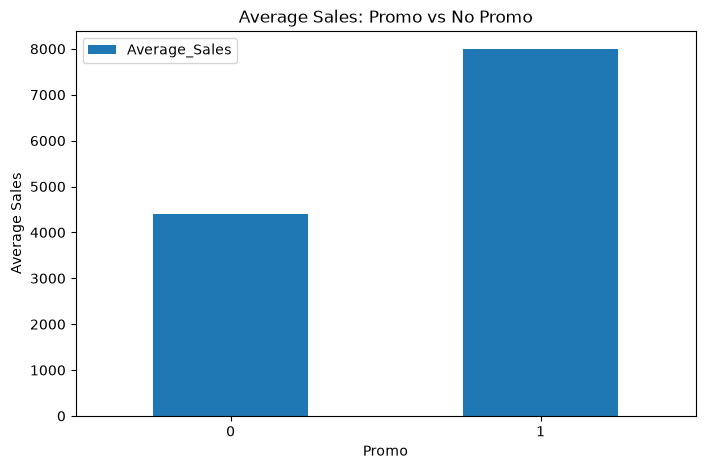

In [17]:
promo_analysis.plot(
    y="Average_Sales",
    kind="bar",
    figsize=(8, 5),
    title="Average Sales: Promo vs No Promo"
)

plt.xlabel("Promo")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

In [18]:
weekday_analysis = df.groupby("DayOfWeek").agg(
    Average_Sales=("Sales", "mean"),
    Average_Customers=("Customers", "mean"),
    Total_Sales=("Sales", "sum")
)

weekday_analysis

,Average_Sales,Average_Customers,Total_Sales
DayOfWeek,,,
1,7809.044510,813.065791,1130203012
2,7005.244467,760.984615,1020411930
3,6555.884138,721.639666,954962863
4,6247.575913,697.541486,911177709
5,6723.274305,743.150742,980555941
6,5847.562599,657.112237,846317735
7,204.183189,35.786817,29551433


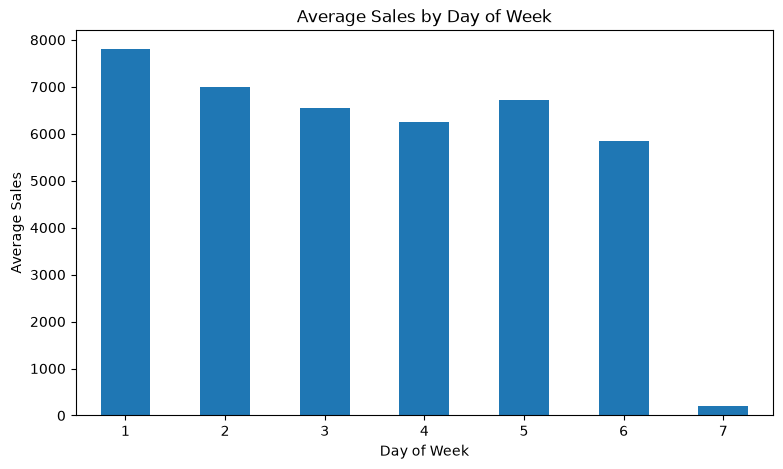

In [19]:
weekday_analysis["Average_Sales"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Sales by Day of Week"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

In [20]:
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Sales"]
      .sum()
)

monthly_sales

Date
2013-01    180132207
2013-02    171534275
2013-03    201180369
2013-04    183431432
2013-05    185411063
2013-06    180702351
2013-07    208843882
2013-08    198042727
2013-09    178053963
2013-10    187662330
2013-11    196170924
2013-12    231710561
2014-01    187752787
2014-02    178924677
2014-03    193019854
2014-04    194544977
2014-05    194693257
2014-06    190047051
2014-07    173892707
2014-08    163748475
2014-09    164516168
2014-10    164216398
2014-11    173327953
2014-12    202120592
2015-01    198843730
2015-02    178275458
2015-03    205631683
2015-04    197918886
2015-05    189143897
2015-06    207363373
2015-07    212322616
Freq: M, Name: Sales, dtype: int64

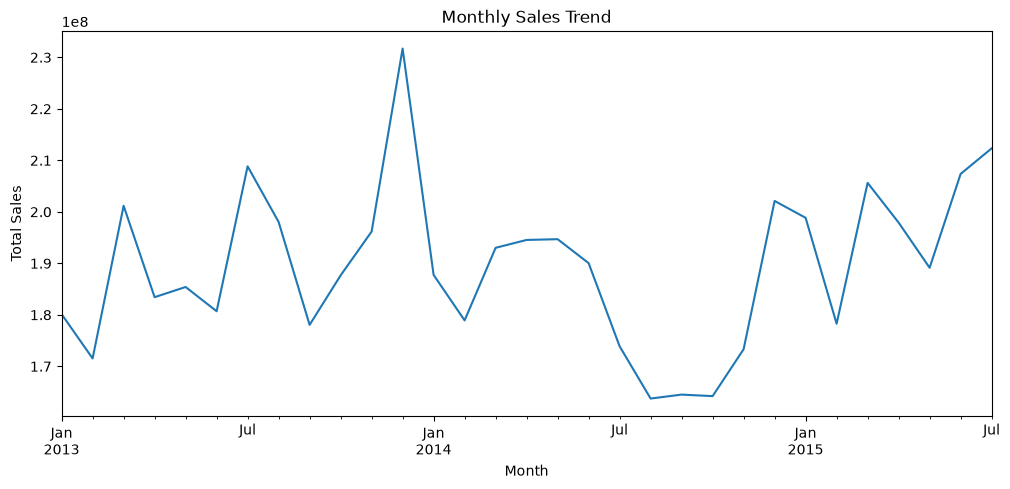

In [21]:
monthly_sales.plot(
    figsize=(12, 5),
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

In [22]:
print(df[["Sales","Customers"]].corr())

              Sales  Customers
Sales      1.000000   0.894711
Customers  0.894711   1.000000


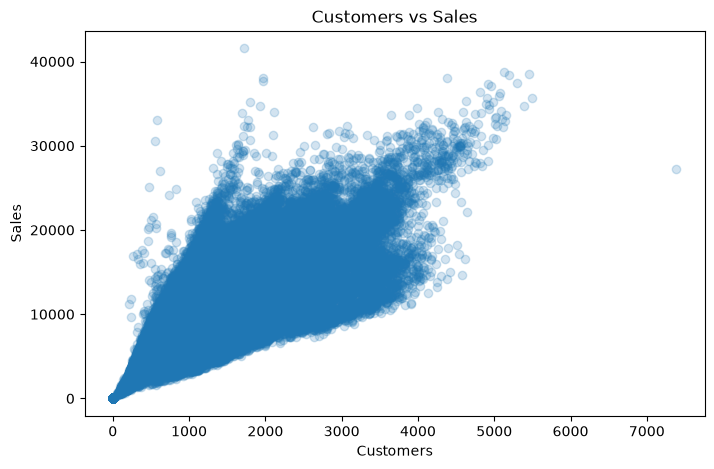

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Customers"],
    df["Sales"],
    alpha=0.2
)

plt.xlabel("Customers")
plt.ylabel("Sales")
plt.title("Customers vs Sales")

plt.show()

In [24]:
df.groupby("Open").agg(
    Records=("Sales", "count"),
    Average_Sales=("Sales", "mean"),
    Total_Sales=("Sales", "sum")
)

,Records,Average_Sales,Total_Sales
Open,,,
0,172817,0.000000,0
1,844392,6955.514291,5873180623
